# Task 3 missing-value EDA 2 (V9a)

คำถาม: หลัง V9a เติม `prev_month_spending` แล้ว แถวที่หาย 2 ช่องขึ้นไปยังได้ 0.7907 เทียบกับ 0.8000 ของแถวที่หาย 0–1 ช่อง มี feature **อื่น** ไหมที่ (a) ทำให้คะแนนตกเมื่อหาย และ (b) เติมจาก feature อื่นได้

ใช้ `train.csv` + OOF ของ V9a (`experiments/task3/model/champion/task3_oof.csv`) วิเคราะห์อย่างเดียว ไม่แก้โมเดล วิธีเดียวกับ `missing_eda.ipynb`

## Imports

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold

pd.set_option('display.width', 200)  # keep wide tables on one line instead of "..."


## Setup

In [2]:
# Find the repo root (the folder with `run.py`), move there and add it to `sys.path`, so paths like `baseline/...` and `import pis` work wherever the kernel started.
ROOT = Path.cwd().resolve()
while not (ROOT / 'run.py').exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('run.py not found; open this notebook inside the repo')
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from pis.common import DEFAULT_DATA  # ../cpe342-kaggle-main, needs ROOT on sys.path
from pis.tabular import _score       # the competition metric: 1 / (1 + sum|y - p| / sum y)
print(f"repo root: {ROOT}")

repo root: C:\Users\acer\Desktop\cpe342\project\player-intelligence-system-cpe342


## Load data & check the V9a OOF

OOF ต้องเรียงแถวเดียวกับ `train.csv` (เช็ค `player_id`) และต้องได้ 0.7947 ตาม `champion.json`

In [3]:
tr = pd.read_csv(DEFAULT_DATA / '03_regression' / 'train.csv')       # train
o = pd.read_csv('experiments/task3/model/champion/task3_oof.csv')      # V9a out-of-fold predictions
assert (tr['player_id'].to_numpy() == o['player_id'].to_numpy()).all(), 'OOF row order differs from train.csv'
assert np.allclose(tr['spending_30d'], o['target'])

y, pred = tr['spending_30d'].to_numpy(), o['prediction'].to_numpy()
err = np.abs(y - pred)
E, Y = err.sum(), y.sum()   # the metric is 1 / (1 + E / Y)
feats = [c for c in tr.columns if c not in ('player_id', 'spending_30d')]  # the 32 features
oof = _score(y, pred)
assert abs(oof - 0.7947) < 1e-4, oof
print(f"V9a OOF {oof:.4f} | rows {len(tr):,} | features {len(feats)}")

V9a OOF 0.7947 | rows 104,000 | features 32


## 1. Score with each feature missing vs present

ก่อนดูทีละ feature ดูคำถามตั้งต้นก่อน: กลุ่มที่หาย 2+ ช่องต่ำกว่าที่สุ่มได้ไหม

จากนั้นทุก feature: คะแนน V9a ในแถวที่ feature หาย เทียบกับแถวที่มีค่า และเทียบกับคะแนนของกลุ่มสุ่มขนาดเท่ากัน 2,000 ครั้ง (เหมือน `missing_eda.ipynb` section 4) `null_share` = สัดส่วนกลุ่มสุ่มที่ได้คะแนนเท่าหรือต่ำกว่ากลุ่มที่หาย ยิ่งต่ำยิ่งไม่ใช่ความบังเอิญ

metric หารด้วยยอดรวมของกลุ่ม กลุ่มที่ target เล็กกว่าปกติจะได้คะแนนต่ำลงเองแม้ error เท่าเดิม จึงแสดง `mae` (|error| เฉลี่ยต่อแถว) และ `target_share / row_share` ด้วย เพื่อแยกว่าคะแนนตกเพราะโมเดลพลาดมากขึ้น หรือเพราะกลุ่มนั้นใช้เงินน้อยกว่า

In [4]:
N_DRAWS = 2000

def null_scores(n, seed=342):
    """Scores of N_DRAWS random groups of n rows (the same rows can't repeat within a group)."""
    rng = np.random.default_rng(seed)
    idx = np.array([rng.choice(len(y), n, replace=False) for _ in range(N_DRAWS)])
    return 1 / (1 + err[idx].sum(axis=1) / y[idx].sum(axis=1))

n_missing = tr[feats].isna().sum(axis=1).to_numpy()
many = n_missing >= 2
null_many = null_scores(int(many.sum()))
s_many, s_few = _score(y[many], pred[many]), _score(y[~many], pred[~many])
lo, hi = np.percentile(null_many, [2.5, 97.5])
print(f"2+ missing: {many.sum():,} rows, score {s_many:.4f} vs 0-1 missing {s_few:.4f}; random groups of that size: "
      f"95% in [{lo:.4f}, {hi:.4f}], at or below {s_many:.4f}: {(null_many <= s_many).mean():.2%}")

2+ missing: 58,544 rows, score 0.7907 vs 0-1 missing 0.8000; random groups of that size: 95% in [0.7913, 0.7982], at or below 0.7907: 1.30%


In [5]:
rows = []
for c in feats:
    m = tr[c].isna().to_numpy()
    null = null_scores(int(m.sum()))
    s_miss, s_pres = _score(y[m], pred[m]), _score(y[~m], pred[~m])
    rows.append({'feature': c, 'rows_missing': int(m.sum()), 'score_missing': s_miss, 'score_present': s_pres,
                 'gap': s_miss - s_pres, 'null_share': (null <= s_miss).mean(),
                 'mae_missing': err[m].mean(), 'mae_present': err[~m].mean(),
                 'target_share / row_share': (y[m].sum() / Y) / m.mean()})
by_feat = pd.DataFrame(rows).set_index('feature').sort_values('gap')
by_feat['significant'] = np.where(by_feat['null_share'] < 0.025, 'yes', '')
print(f"significant (null_share < 2.5%): {(by_feat['significant'] == 'yes').sum()} of {len(by_feat)}; "
      f"expected by chance alone with {len(by_feat)} features: about {0.025 * len(by_feat):.1f}")

(by_feat.style
    .format({'rows_missing': '{:,}', 'score_missing': '{:.4f}', 'score_present': '{:.4f}', 'gap': '{:+.4f}',
             'null_share': '{:.2%}', 'mae_missing': '{:,.0f}', 'mae_present': '{:,.0f}',
             'target_share / row_share': '{:.3f}'})
    .bar(subset='gap', color=['#e34948', '#2a78d6'], align=0)
    .set_caption('Table 1. V9a score with each feature missing vs present, sorted by gap'))

significant (null_share < 2.5%): 2 of 32; expected by chance alone with 32 features: about 0.8


,rows_missing,score_missing,score_present,gap,null_share,mae_missing,mae_present,target_share / row_share,significant
feature,,,,,,,,,
avg_session_length,"6,003",0.7696,0.7962,-0.0265,0.10%,"2,828","2,704",0.900,yes
account_age_days,"6,012",0.7785,0.7957,-0.0173,2.30%,"2,888","2,700",0.967,yes
vip_status,"6,189",0.7789,0.7958,-0.0169,3.15%,"2,994","2,693",1.005,
historical_spending,"6,035",0.7797,0.7957,-0.0160,3.45%,"2,906","2,699",0.980,
avg_transaction_value,"5,991",0.7802,0.7957,-0.0155,4.15%,"3,028","2,692",1.024,
days_since_last_login,"6,035",0.7821,0.7955,-0.0134,5.65%,"2,957","2,696",1.011,
seasonal_spending_pattern,"5,910",0.7837,0.7954,-0.0117,10.20%,"2,886","2,701",0.996,
discount_rate_used,"6,103",0.7851,0.7953,-0.0102,10.65%,"2,713","2,711",0.944,
guild_membership,"6,072",0.7861,0.7953,-0.0091,14.35%,"2,876","2,701",1.007,


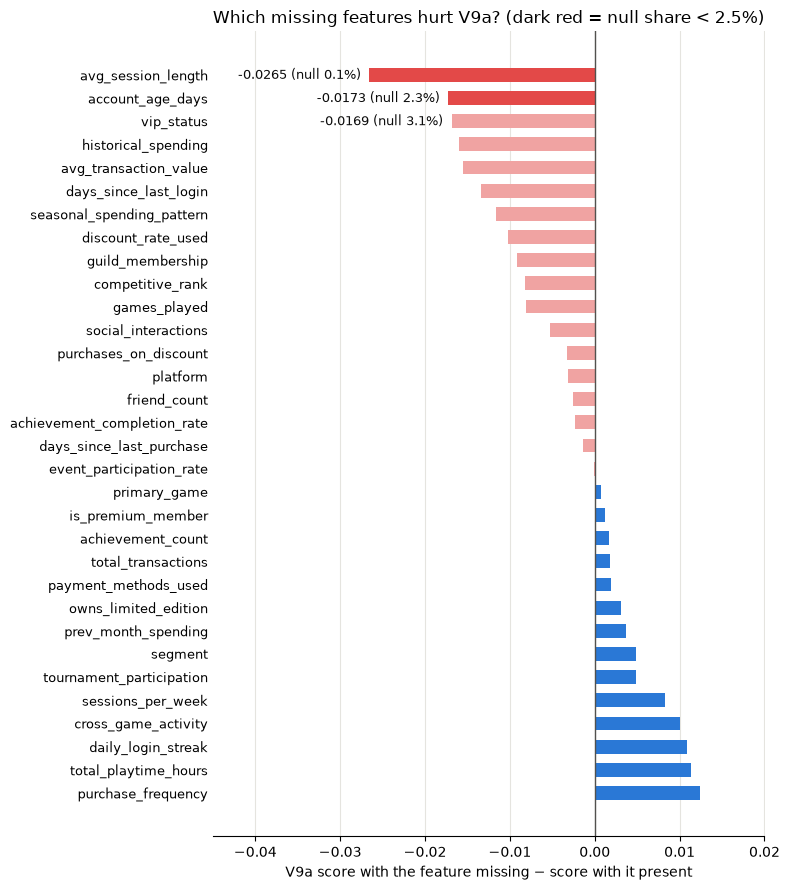

In [6]:
g = by_feat['gap'].sort_values(ascending=False)  # barh draws bottom-up, so the most negative ends on top
fig, ax = plt.subplots(figsize=(8, 9))
colors = ['#e34948' if by_feat.loc[c, 'significant'] == 'yes' else ('#f0a3a2' if v < 0 else '#2a78d6')
          for c, v in g.items()]  # dark red = significantly worse when missing
ax.barh(g.index, g.values, height=0.6, color=colors)
ax.axvline(0, color='#52514e', linewidth=1)
for name, v in g.tail(3).items():  # label the 3 largest drops
    ax.text(v - 0.001, name, f"{v:+.4f} (null {by_feat.loc[name, 'null_share']:.1%})", va='center', ha='right',
            fontsize=9, color='#0b0b0b')
ax.set_xlim(-0.045, 0.02)
ax.set_xlabel('V9a score with the feature missing − score with it present')
ax.set_title('Which missing features hurt V9a? (dark red = null share < 2.5%)', loc='left')
ax.grid(axis='x', color='#e5e4df', linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.tick_params(axis='y', length=0, labelsize=9)
plt.tight_layout()
plt.show()

**NOTE:**

The 2+ missing group still scores lower than 98.7% of random groups of its size (null share 1.3%), so the gap is real. Per feature, only `avg_session_length` (null share 0.1%) and `account_age_days` (2.3%) pass the 2.5% line. That is about what chance gives with 32 features (expected 0.8), so only `avg_session_length` really stands out.

Part of its gap is target mix, not model error: rows missing `avg_session_length` hold 0.90× their share of total spend, so the score falls even at equal error. Its mean |error| is only about 5% higher than when present (2,828 vs 2,704). `prev_month_spending` now scores *better* when missing (+0.0037), which is the V9a fix.

## 2. Can each feature be imputed? (label-free)

ทุก feature: เทรน HistGradientBoosting 3-fold บนแถวที่มีค่า ทายจาก feature อื่น (**ไม่ใช้** `spending_30d` และไม่ใช้แถว test) แล้ววัด R² และ Spearman ระหว่างค่าที่ทายกับค่าจริง (out-of-fold) feature ที่ช่วยทายวัดด้วย permutation importance (R² ที่หายไปเมื่อสลับค่า) บน 5,000 แถวของ fold สุดท้าย

ทายค่าดิบ (ไม่ใช่ log) ทุก feature เพื่อให้เทียบกันได้ `platform` กับ `primary_game` เป็นรหัสหมวดหมู่ที่ไม่มีลำดับ R² ของสองตัวนี้จึงไม่มีความหมาย

In [7]:
assert 'spending_30d' not in feats
rows = []
for c in feats:
    present = tr[c].notna()
    X = tr.loc[present, [f for f in feats if f != c]]  # the other 31 features only, train rows only
    t = tr.loc[present, c].to_numpy()
    p = np.zeros(len(t))
    for a, b in KFold(3, shuffle=True, random_state=342).split(X):
        model = HistGradientBoostingRegressor(random_state=342).fit(X.iloc[a], t[a])
        p[b] = model.predict(X.iloc[b])
    pi = permutation_importance(model, X.iloc[b][:5000], t[b][:5000], n_repeats=3, random_state=342, scoring='r2')
    top = pd.Series(pi.importances_mean, X.columns).sort_values(ascending=False).head(2)
    rows.append({'feature': c, 'R²': r2_score(t, p), 'Spearman': spearmanr(t, p)[0],
                 'top predictors (R² drop)': ', '.join(f"{k} {v:.2f}" for k, v in top.items() if v > 0.01) or '—'})
imput = pd.DataFrame(rows).set_index('feature').sort_values('R²', ascending=False)
(imput.style
    .format({'R²': '{:.3f}', 'Spearman': '{:.3f}'})
    .bar(subset='R²', color='#86b6ef', vmin=0, vmax=1)
    .set_caption('Table 2. Label-free imputability, 3-fold out-of-fold on rows where the feature is present'))

,R²,Spearman,top predictors (R² drop)
feature,,,
historical_spending,0.991,0.991,"prev_month_spending 1.47, avg_transaction_value 0.07"
prev_month_spending,0.985,0.992,"historical_spending 1.74, avg_transaction_value 0.05"
total_transactions,0.984,0.994,"purchases_on_discount 2.50, discount_rate_used 0.63"
purchases_on_discount,0.978,0.991,"total_transactions 1.29, discount_rate_used 0.49"
is_premium_member,0.948,0.625,vip_status 1.89
segment,0.946,0.943,"event_participation_rate 1.09, historical_spending 0.13"
avg_transaction_value,0.932,0.981,"total_transactions 4.66, historical_spending 3.70"
discount_rate_used,0.931,0.958,"purchases_on_discount 2.97, total_transactions 1.34"
event_participation_rate,0.770,0.843,"segment 1.32, historical_spending 0.05"


**NOTE:**

Imputability splits the features in two. The spend and purchase features (`historical_spending`, `prev_month_spending`, `total_transactions`, `purchases_on_discount`, `avg_transaction_value`, `discount_rate_used`, `segment`, `is_premium_member`) are near copies of each other (R² 0.93–0.99). The activity and account features (`avg_session_length`, `account_age_days`, `days_since_last_login`, logins, sessions, playtime) can hardly be predicted at all (R² < 0.1). The two features that hurt most when missing are both in the second group.

## 3. Which features carry shared information?

Spearman correlation ของ feature ดิบทุกคู่ (ใช้แถวที่มีค่าทั้งคู่) เรียงลำดับด้วย hierarchical clustering ให้ feature ที่ไปด้วยกันอยู่ติดกัน กลุ่มที่สีเข้มเป็นก้อนคือ feature ที่เติมกันเองได้ ส่วน feature ที่ไม่มีคู่สีเข้มเลย ถ้าหายก็ไม่มีตัวอื่นแทน

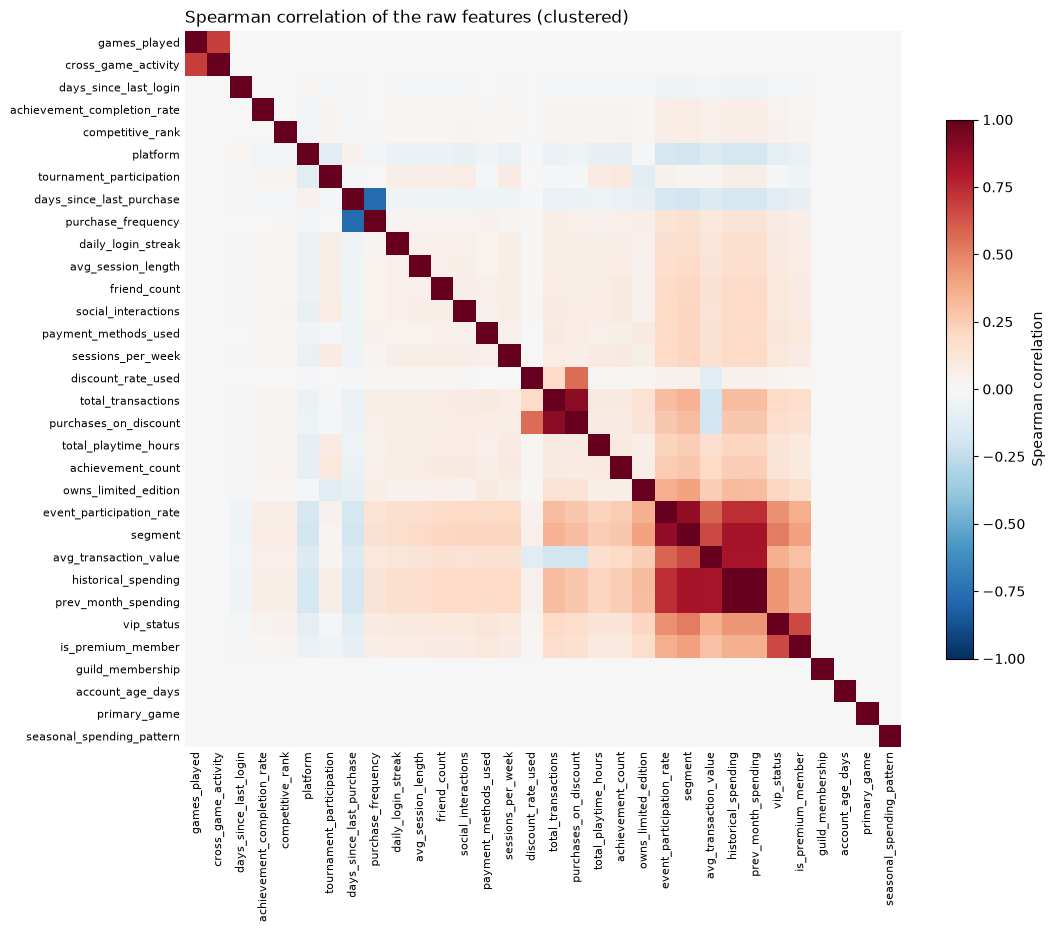

In [8]:
rho = tr[feats].corr(method='spearman')
order = leaves_list(linkage(squareform(1 - rho.abs().to_numpy(), checks=False), method='average'))
rho = rho.iloc[order, order]

fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(rho.to_numpy(), cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(rho)), rho.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(rho)), rho.index, fontsize=8)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
cbar = fig.colorbar(im, ax=ax, shrink=0.7)
cbar.set_label('Spearman correlation')
ax.set_title('Spearman correlation of the raw features (clustered)', loc='left')
plt.tight_layout()
plt.show()

**NOTE:**

The largest block is spend history (`prev_month_spending`, `historical_spending`, `avg_transaction_value`) with `segment`, `event_participation_rate`, `vip_status` and `is_premium_member`. A second block holds the purchase counts (`total_transactions`, `purchases_on_discount`, `discount_rate_used`). Two pairs stand alone: `games_played`–`cross_game_activity` and `days_since_last_purchase`–`purchase_frequency`. Features in a block fill in for each other, which is why V9a's imputation of `prev_month_spending` worked. `avg_session_length` has only weak links (about 0.2) to the spend block, and `account_age_days` has none at all, so nothing can stand in for them when they are missing.

## 4. Shortlist and oracle

shortlist = feature ที่ gap มีนัยสำคัญ (`null_share` < 2.5%) **และ** เติมได้ (R² > 0.3) ทั้งสองข้อตั้งไว้ก่อนเห็นข้อมูล

oracle เหมือน `missing_eda.ipynb` section 6: ถ้าแถวที่ feature หายมี error per THB เท่ากับแถวที่มีค่า OOF จะขึ้นเท่าไร (ขอบบน) สำหรับ shortlist คิดรวม: แถวที่หายอย่างน้อยหนึ่งตัวใน shortlist ได้ error rate ของแถวที่ไม่หายเลย

In [9]:
table4 = by_feat[['rows_missing', 'gap', 'null_share']].join(imput[['R²', 'Spearman']])
table4['significant gap'] = table4['null_share'] < 0.025
table4['imputable (R² > 0.3)'] = table4['R²'] > 0.3
table4['shortlist'] = table4['significant gap'] & table4['imputable (R² > 0.3)']
shortlist = table4.index[table4['shortlist']].tolist()

def oracle(cols):
    """OOF if rows missing any of `cols` had the error per THB of rows missing none of them."""
    m = tr[cols].isna().any(axis=1).to_numpy()
    rate = err[~m].sum() / y[~m].sum()
    e_new = E - err[m].sum() + rate * y[m].sum()
    return int(m.sum()), 1 / (1 + e_new / Y) - oof

print(f"shortlist: {shortlist if shortlist else 'empty'}")
if shortlist:
    n, gain = oracle(shortlist)
    print(f"oracle for the shortlist ({n:,} rows): OOF {oof:.4f} -> {oof + gain:.4f} ({gain:+.4f})")

yes = lambda v: 'yes' if v else ''
(table4[table4['significant gap'] | (table4['null_share'] < 0.05)]
    .assign(**{k: lambda d, k=k: d[k].map(yes) for k in ['significant gap', 'imputable (R² > 0.3)', 'shortlist']})
    .style.format({'rows_missing': '{:,}', 'gap': '{:+.4f}', 'null_share': '{:.2%}', 'R²': '{:.3f}', 'Spearman': '{:.3f}'})
    .set_caption('Table 4. Features with null share below 5%: significant gap (below 2.5%) and imputability'))

shortlist: empty


,rows_missing,gap,null_share,R²,Spearman,significant gap,imputable (R² > 0.3),shortlist
feature,,,,,,,,
avg_session_length,"6,003",-0.0265,0.10%,0.049,0.210,yes,,
account_age_days,"6,012",-0.0173,2.30%,-0.001,-0.003,yes,,
vip_status,"6,189",-0.0169,3.15%,0.672,0.600,,yes,
historical_spending,"6,035",-0.0160,3.45%,0.991,0.991,,yes,
avg_transaction_value,"5,991",-0.0155,4.15%,0.932,0.981,,yes,


**Sensitivity (not part of the decision):** the shortlist rule uses fixed lines, so the near misses also get an oracle here to show whether a looser line would change the answer. "Near miss" means null share < 5% and R² > 0.3, i.e. `vip_status`, `historical_spending` and `avg_transaction_value`. `avg_session_length` gets one too, as if it could be imputed.

In [10]:
near = table4.index[(table4['null_share'] < 0.05) & table4['imputable (R² > 0.3)']].tolist()
sens = []
for label, cols in [*[(c, [c]) for c in near], ('all near misses together', near),
                    ('avg_session_length (not imputable, R² %.2f)' % imput.loc['avg_session_length', 'R²'], ['avg_session_length'])]:
    n, gain = oracle(cols)
    sens.append({'rows': label, 'rows affected': n, 'OOF oracle': oof + gain, 'oracle gain': gain})
(pd.DataFrame(sens).set_index('rows').style
    .format({'rows affected': '{:,}', 'OOF oracle': '{:.4f}', 'oracle gain': '{:+.4f}'})
    .set_caption(f'Oracle upper bounds (error per THB of the present rows); V9a OOF {oof:.4f}, bar +0.002'))

,rows affected,OOF oracle,oracle gain
rows,,,
vip_status,"6,189",0.7958,+0.0010
historical_spending,"6,035",0.7957,+0.0009
avg_transaction_value,"5,991",0.7957,+0.0009
all near misses together,"17,174",0.7981,+0.0034
"avg_session_length (not imputable, R² 0.05)","6,003",0.7962,+0.0014


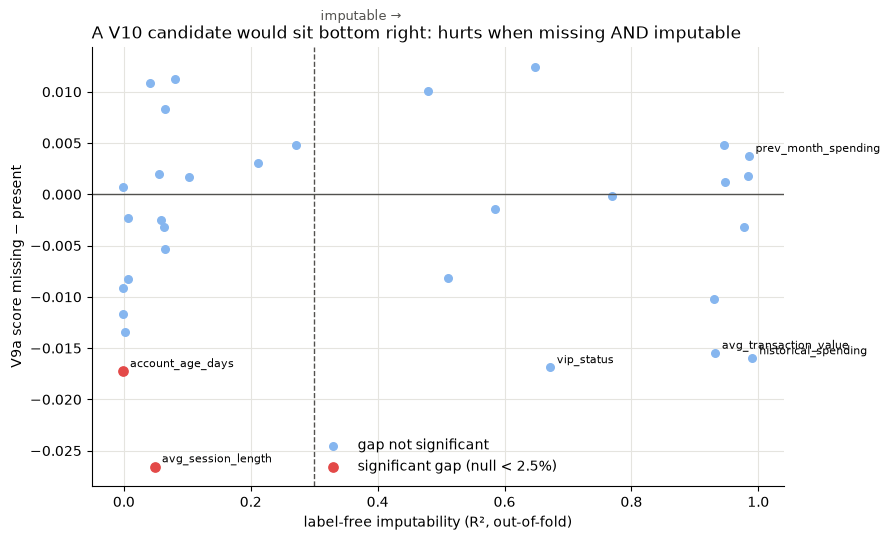

In [11]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sig = table4['significant gap']
ax.scatter(table4.loc[~sig, 'R²'], table4.loc[~sig, 'gap'], s=30, color='#86b6ef', label='gap not significant')
ax.scatter(table4.loc[sig, 'R²'], table4.loc[sig, 'gap'], s=45, color='#e34948', label='significant gap (null < 2.5%)')
for c in [*table4.index[sig], *near, 'prev_month_spending']:
    ax.annotate(c, (table4.loc[c, 'R²'], table4.loc[c, 'gap']), xytext=(5, 3), textcoords='offset points', fontsize=8)
ax.axvline(0.3, color='#52514e', linestyle='--', linewidth=1)
ax.axhline(0, color='#52514e', linewidth=1)
ax.text(0.31, 0.017, 'imputable →', fontsize=9, color='#52514e')
ax.set_xlabel('label-free imputability (R², out-of-fold)')
ax.set_ylabel('V9a score missing − present')
ax.set_title('A V10 candidate would sit bottom right: hurts when missing AND imputable', loc='left')
ax.legend(frameon=False, loc='lower center')
ax.grid(color='#e5e4df', linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

**NOTE:**

The bottom-right corner has no significant feature. The two features that hurt significantly when missing cannot be imputed (R² 0.05 and −0.00). The imputable near misses (`vip_status`, `historical_spending`, `avg_transaction_value`) are not significant at 2.5%. Their oracles are +0.0009 to +0.0010 each and **+0.0034 together**, above the +0.002 bar. But that upper bound has already been tested for two of them: V9b imputed `historical_spending` and `avg_transaction_value` on top of prev and gained only +0.0002 over V9a (`model/v9_impute/v9_impute_results.md`). That leaves `vip_status` on its own at +0.0010, below the bar.

## Summary

- **V9a OOF:** ได้ 0.7947 ตรงกับ `champion.json` และ `player_id` เรียงตรงกับ `train.csv`
- **คำถามตั้งต้น:** กลุ่มที่หาย 2+ ช่องได้ 0.7907 เทียบกับ 0.8000 ของกลุ่ม 0–1 ช่อง ยังต่ำกว่ากลุ่มสุ่มขนาดเท่ากัน 98.7% (null share 1.3%) จึงเป็นช่องว่างจริง แต่ไม่ได้มาจาก feature ที่เติมได้ตัวไหน
- **ทีละ feature (ตาราง 1):** ผ่านเกณฑ์ 2.5% แค่ 2 ตัว คือ `avg_session_length` (−0.0265, null 0.1%) และ `account_age_days` (−0.0173, 2.3%) ใกล้กับที่คาดได้จากความบังเอิญเมื่อดู 32 ตัว (0.8 ตัว) ช่องว่างของ `avg_session_length` ส่วนหนึ่งมาจาก target mix (กลุ่มนี้ใช้เงิน 0.90 เท่าของสัดส่วนแถว) |error| เฉลี่ยสูงกว่าแค่ประมาณ 5% ส่วน `prev_month_spending` ตอนนี้ถ้าหายกลับดีกว่า (+0.0037) ซึ่งเป็นผลของ V9a
- **เติมค่าได้ไหม (ตาราง 2):** feature แบ่งเป็นสองพวก พวกประวัติการใช้จ่ายและการซื้อเติมกันเองได้ดี (R² 0.93–0.99) พวก activity และ account แทบเติมไม่ได้ (R² < 0.1) สองตัวที่ผ่านเกณฑ์อยู่ในพวกหลัง (R² 0.05 และ −0.00)
- **Correlation:** ก้อนใหญ่สุดคือประวัติการใช้จ่าย + `segment`, `event_participation_rate`, `vip_status`, `is_premium_member` อีกก้อนคือจำนวนการซื้อ `avg_session_length` เชื่อมกับก้อนใหญ่แค่อ่อนๆ และ `account_age_days` ไม่สัมพันธ์กับตัวไหนเลย ถ้าหายจึงไม่มีตัวอื่นแทน
- **Shortlist (ตาราง 4):** ว่าง ไม่มี feature ที่ทั้ง gap มีนัยสำคัญและเติมได้
- **Sensitivity (ไม่ได้ใช้ตัดสิน):** ตัวที่เกือบผ่าน (`vip_status` null 3.2%, `historical_spending` 3.5%, `avg_transaction_value` 4.2%, R² 0.67–0.99) มี oracle ตัวละ +0.0009 ถึง +0.0010 รวมกัน +0.0034 แต่ `historical_spending` กับ `avg_transaction_value` ถูกเติมไปแล้วใน V9b ซึ่งดีกว่า V9a แค่ +0.0002 ขอบบนนี้จึงไม่เกิดขึ้นจริง เหลือ `vip_status` ตัวเดียว +0.0010 ต่ำกว่า +0.002

**Decision ตามกฎที่ตั้งไว้: ปิด Task 3** ใช้ V9a refit (public LB 0.82369) เป็น model สุดท้ายของงาน 3

| เกณฑ์ | ผล | ผ่านไหม |
|---|---|---|
| shortlist ไม่ว่าง (null share < 2.5% และ R² > 0.3) | ว่าง: ตัวที่ gap มีนัยสำคัญเติมไม่ได้ (R² 0.05, −0.00) | ไม่ผ่าน |
| oracle ของ shortlist > +0.002 OOF | ไม่ได้คำนวณ (shortlist ว่าง) | — |

ช่องว่างที่เหลือของกลุ่มหาย 2+ ช่องมาจาก feature activity/account ที่ไม่มี feature อื่นแทนได้ การเติมค่าแบบไม่ใช้ label จึงไปต่อไม่ได้แล้ว